## 1. Import all the Liberaries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve)

import warnings
warnings.filterwarnings('ignore')

import sys

sys.path.append('../')
from src.data_preprocessing import DataPreprocessor

print("ALL LIBRARIES IMPORTED")

ALL LIBRARIES IMPORTED


## 2. Load and preprcess data

In [2]:
# Load and preprocess data 
preprocessor = DataPreprocessor()

df = preprocessor.load_data("../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()


Loading data from ../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv ...

 Data Loaded


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
x_train, x_test, y_train, y_test = preprocessor.prepare_data(df)


++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
STARTING DATA PREPROCESSING PIPELINE
Filled missing values 

Creating new features....
Tenure range: 0 to 72
✅ Created 3 new features
    - tenure_group: [0 2 1 3]
    - avg_monthly_per_tenure: min=9.18, max=1397.47
    - num_services: min=0, max=5


    - Encoded MultipleLines: 3 classes
    - Encoded InternetService: 3 classes
    - Encoded OnlineSecurity: 3 classes
    - Encoded OnlineBackup: 3 classes
    - Encoded DeviceProtection: 3 classes
    - Encoded TechSupport: 3 classes
    - Encoded StreamingTV: 3 classes
    - Encoded StreamingMovies: 3 classes
    - Encoded Contract: 3 classes
    - Encoded PaymentMethod: 4 classes
✅ Encoded 15 categorical features

📊 Train-Test Spilt:
    Train set: 5634 samples (80%)
    Test set: 1409 samples (20.000000%)
FEATURES SCALED!!!

✅ PREPROCESSING COMPLETE


In [4]:
print(f"\n📊 Final Dataset Summary:")
print(f"Training samples: {x_train.shape[0]}")
print(f"Test samples: {x_test.shape[0]}")
print(f"Number of features: {x_train.shape[1]}")
print(f"Churn rate (train): {y_train.mean() * 100:.2f}%")
print(f"Churn rate (test): {y_test.mean() * 100:.2f}%")



📊 Final Dataset Summary:
Training samples: 5634
Test samples: 1409
Number of features: 22
Churn rate (train): 26.54%
Churn rate (test): 26.54%


## Model Training

In [5]:
models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Desion Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(n_estimators = 100, max_depth = 5, random_state=42, eval_metric='logloss')
}
models

{'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
 'Desion Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
 'Random Forest': RandomForestClassifier(max_depth=10, random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric='logloss',
               feature_types=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=None, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=100,
        

In [6]:
print("x_train:", x_train.shape)
print("x_test :", x_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

x_train: (5634, 22)
x_test : (1409, 22)
y_train: (5634,)
y_test : (1409,)


In [7]:
# Train all models
results = {}
print("TRAINING STARTED!!!.")

for name, model in models.items():

    print(f"\nTraining started: {name}")

    # Train
    model.fit(x_train, y_train)

    # Predict
    y_pred = model.predict(x_test)
    y_pred_proba = model.predict_proba(x_test)[:, 1]

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    # Store results
    results[name] = {
        'model': model,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }

    print(f"{name} trained")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")

print("TRAINING COMPLETED!!!.")


TRAINING STARTED!!!.

Training started: Logistic Regression


Logistic Regression trained
Accuracy: 0.8034
Precision: 0.6622
Recall: 0.5294
F1 Score: 0.5884
ROC AUC: 0.8460

Training started: Desion Tree
Desion Tree trained
Accuracy: 0.7601
Precision: 0.5497
Recall: 0.5321
F1 Score: 0.5408
ROC AUC: 0.7542

Training started: Random Forest
Random Forest trained
Accuracy: 0.8020
Precision: 0.6644
Recall: 0.5134
F1 Score: 0.5792
ROC AUC: 0.8372

Training started: Gradient Boosting
Gradient Boosting trained
Accuracy: 0.8020
Precision: 0.6655
Recall: 0.5107
F1 Score: 0.5779
ROC AUC: 0.8429

Training started: XGBoost
XGBoost trained
Accuracy: 0.7878
Precision: 0.6190
Recall: 0.5214
F1 Score: 0.5660
ROC AUC: 0.8208
TRAINING COMPLETED!!!.


In [8]:
# Model comparison
model_compare = pd.DataFrame({
    'Model':list(results.keys()),
    'Accuracy':[results[m]['accuracy'] for m in results],
    'Precision':[results[m]['precision'] for m in results],
    'F1-Score':[results[m]['f1'] for m in results],
    'ROC-AUC':[results[m]['roc_auc'] for m in results],
    'Recall':[results[m]['recall'] for m in results],
})
print(model_compare)
    

                 Model  Accuracy  Precision  F1-Score   ROC-AUC    Recall
0  Logistic Regression  0.803407   0.662207  0.588410  0.846010  0.529412
1          Desion Tree  0.760114   0.549724  0.540761  0.754229  0.532086
2        Random Forest  0.801987   0.664360  0.579186  0.837225  0.513369
3    Gradient Boosting  0.801987   0.665505  0.577912  0.842876  0.510695
4              XGBoost  0.787793   0.619048  0.566038  0.820774  0.521390


In [9]:
model_compare = model_compare.sort_values('Accuracy', ascending=False)

In [10]:
print(model_compare.to_string(index=False))

              Model  Accuracy  Precision  F1-Score  ROC-AUC   Recall
Logistic Regression  0.803407   0.662207  0.588410 0.846010 0.529412
      Random Forest  0.801987   0.664360  0.579186 0.837225 0.513369
  Gradient Boosting  0.801987   0.665505  0.577912 0.842876 0.510695
            XGBoost  0.787793   0.619048  0.566038 0.820774 0.521390
        Desion Tree  0.760114   0.549724  0.540761 0.754229 0.532086


In [11]:
model_compare.to_csv('../reports/model_comparison.csv', index = False)
print("Saved: Model comparison file in reports")

Saved: Model comparison file in reports


# MOdel Visualisation

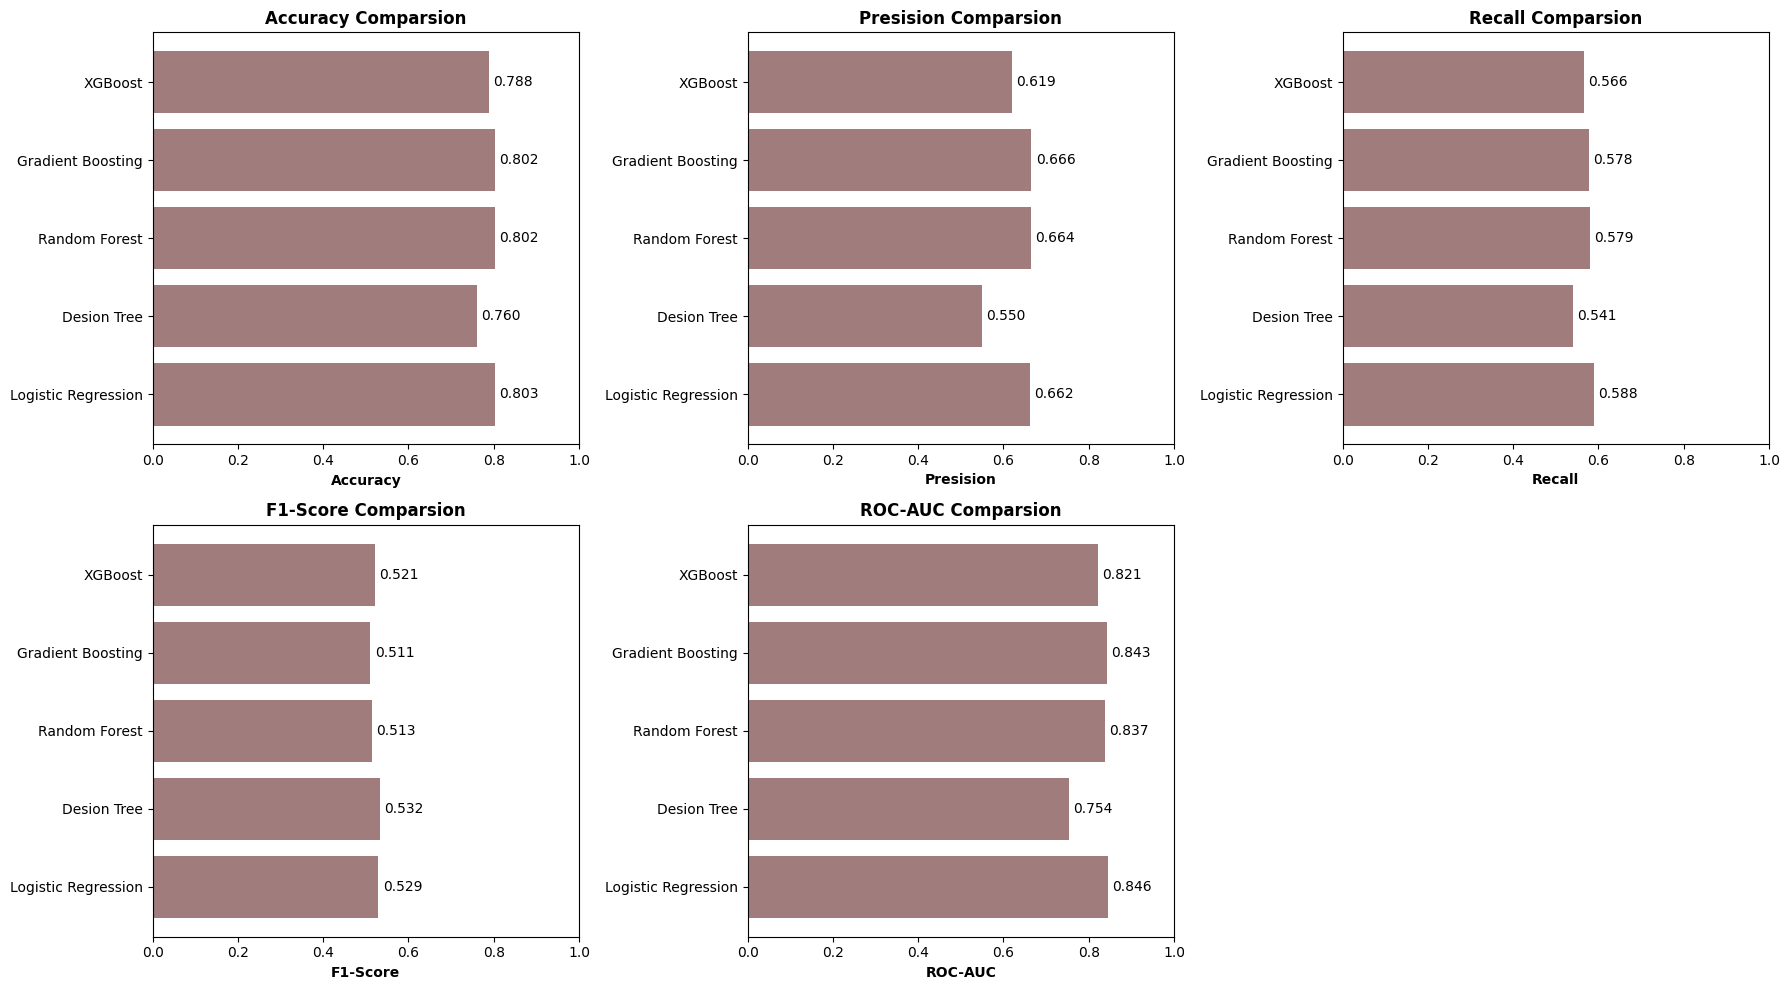

In [12]:
fig, axes = plt.subplots(2,3, figsize=(18, 10))

axes = axes.flatten()

metrics = ['accuracy', 'precision', 'f1', 'recall', 'roc_auc']

metrics_names = ['Accuracy', 'Presision', 'Recall', 'F1-Score', 'ROC-AUC']

for idx, (metric, metric_name) in enumerate(zip(metrics, metrics_names)):
    values = [results[m][metric] for m in results]
    model_names = list(results.keys())

    axes[idx].barh(model_names, values, color= "#49040485")
    axes[idx].set_xlabel(metric_name, fontweight = 'bold')
    axes[idx].set_xlim(0,1)
    axes[idx].set_title(f'{metric_name} Comparsion', fontweight = 'bold')

    for i, v in enumerate(values):
        axes[idx].text(v + 0.01, i, f'{v:.3f}', va='center')


fig.delaxes(axes[5])
plt.tight_layout()
plt.savefig('../reports/model_comparsion_graph.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
best_model_name = model_compare.iloc[0]['Model']
best_model_result = results[best_model_name]

# best_model_name, best_model_result

print(f"Best Model : {best_model_name}")

Best Model : Logistic Regression


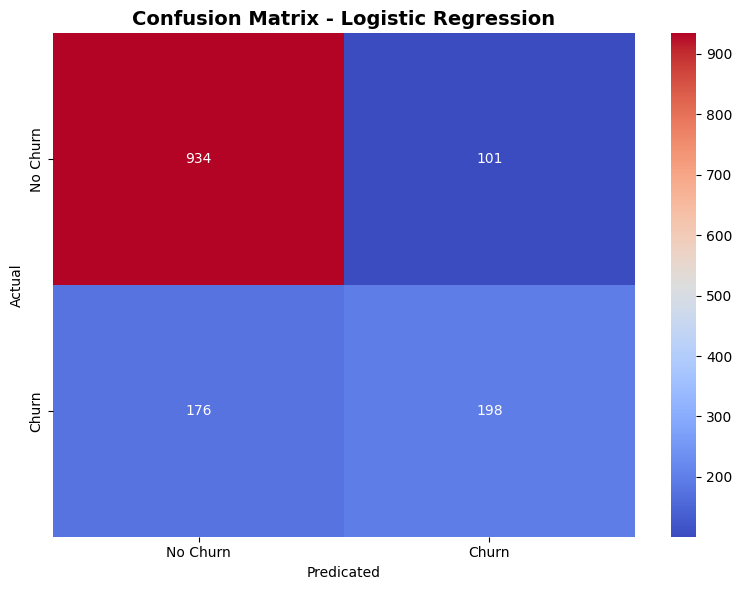

Saved: reports/confussion_metrix.png


In [14]:
cm = confusion_matrix(y_test, best_model_result['y_pred'])

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title(f"Confusion Matrix - {best_model_name}", fontsize=14, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicated')

plt.tight_layout()
plt.savefig('../reports/condusion_metric.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: reports/confussion_metrix.png")